# Nifti Scan Loading and Prediction Example
This notebooks shows how to segment a 3D nifti scan and evaluate the results.

In [1]:
# get current working directory

%reload_ext autoreload
%autoreload 2
from pathlib import Path
import os
cwd = os.getcwd()
print("Current working directory:", cwd)
# set workind directory to the python folder
os.chdir(r"C:/Users/pamar/Documents/GitHub/ML-P2-Sam2/python")
print("Changed working directory to:", os.getcwd())

Current working directory: c:\Users\pamar\Documents\GitHub\ML-P2-Sam2\notebooks
Changed working directory to: C:\Users\pamar\Documents\GitHub\ML-P2-Sam2\python


In [ ]:
from segmentator import *
from src.utils.visualization import * 
from src.utils.eval import *
from src.utils.nifti_utils import *
from src.utils.sam2_utils import *

We create tmb dir to store the images

In [3]:
import shutil
tmp_dir = Path('../tmp')
nifti_scan_path = Path('../notebooks/sample_data/ct.nii.gz')
nifti_gt_path = Path('../notebooks/sample_data/hip_left.nii.gz')
# clean temp and create temp directory
if tmp_dir.exists():
    shutil.rmtree(tmp_dir)
tmp_dir.mkdir()

# check paths exist
assert nifti_scan_path.exists(), f"NIfTI scan path does not exist: {nifti_scan_path}"
assert nifti_gt_path.exists(), f"NIfTI GT path does not exist: {nifti_gt_path}"

In [4]:
scan = load_nifti(nifti_scan_path)
gt = load_nifti(nifti_gt_path)
assert scan.shape == gt.shape, f"Scan and GT shapes do not match: {scan.shape} vs {gt.shape}"

In [5]:
scan_pp = preprocess_nifti(scan)
gt_pp = preprocess_nifti_gt(gt)
print(f"Preprocessed scan shape: {scan_pp.shape}, dtype: {scan_pp.dtype}")

Preprocessed scan shape: (440, 255, 177), dtype: uint8


This detects the slices that contains the bone of interest and extracts them from the scan and gt for evaluation

In [6]:

print("Detecting relevant slices out of total:", gt_pp.shape[0])
min_slice, max_slice = detect_relevant_slices(gt_pp, margin=0.05)
print(f"Relevant slices from {min_slice} to {max_slice}")
ct_slices = extract_ct_slices(scan_pp, min_slice, max_slice)
gt_slices = extract_ct_slices(gt_pp, min_slice, max_slice)
print(f"Extracted CT slices shape: {ct_slices.shape}")
print(f"Extracted GT slices shape: {gt_slices.shape}")

Detecting relevant slices out of total: 440
Relevant slices from 16 to 161
Extracted CT slices shape: (146, 255, 177)
Extracted GT slices shape: (146, 255, 177)


In [7]:
# Save extracted slices for use in sam2 model
save_slices(ct_slices, tmp_dir / "ct_slices")

In [13]:

prompt_idxs = get_prompt_slices(gt_slices, num_slices=4, margin=1)
# for testing, we just get first slice as prompt
prompts = gt_slices[prompt_idxs]
prompt = prompts[0]



In [ ]:
# print current dir
print("Current working directory:", os.getcwd())
file = Path(model_cfg = "../src/base_sam2/sam2/sam2.1/sam2.1_hiera_s.yaml")
# make sure the file exists
assert file.exists(), f"Model config file does not exist: {file}"


Current working directory: C:\Users\pamar\Documents\GitHub\ML-P2-Sam2\python


C:\Users\pamar\AppData\Local\Temp\ipykernel_2836\3670805121.py:3: DeprecationWarning: support for supplying keyword arguments to pathlib.PurePath is deprecated and scheduled for removal in Python 3.14
  file = Path(model_cfg = "../src/base_sam2/sam2/sam2.1/sam2.1_hiera_s.yaml")


We initialize the model

In [11]:
from sam2.sam2_video_predictor import SAM2VideoPredictor
from sam2.build_sam import build_sam2_video_predictor
device = "cuda" if torch.cuda.is_available() else "cpu"
sam2_checkpoint = "../src/base_sam2/checkpoints/sam2.1_hiera_small.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_s.yaml"
assert Path(sam2_checkpoint).exists(), f"SAM2 checkpoint does not exist: {sam2_checkpoint}, please download it first using instructions in the README."


predictor = build_sam2_video_predictor(model_cfg, sam2_checkpoint, device=device)
inference_state = predictor.init_state(str(Path(tmp_dir) / "ct_slices"))

frame loading: 100%|██████████| 146/146 [00:17<00:00,  8.32it/s]


In [14]:
frame_idx, obj_ids, video_res_masks = add_mask_prompt_to_predictor(prompt, prompt_idxs[0], predictor, inference_state)


C:\Users\pamar\Documents\GitHub\ML-P2-Sam2\src\base_sam2\sam2\sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (C:\Users\pamar\Documents\GitHub\ML-P2-Sam2\src\base_sam2\sam2\__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(


We now propagate the masks through the scan slices starting at the prompted slice(s) and moving two in front.

In [15]:

predicted_masks = propagate_video(predictor, inference_state, start_frame=prompt_idxs[0], end_frame=prompt_idxs[0]+2)

propagate in video:   0%|          | 0/3 [00:00<?, ?it/s]C:\Users\pamar\Documents\GitHub\ML-P2-Sam2\src\base_sam2\sam2\sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (C:\Users\pamar\Documents\GitHub\ML-P2-Sam2\src\base_sam2\sam2\__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 3/3 [00:24<00:00,  8.16s/it]


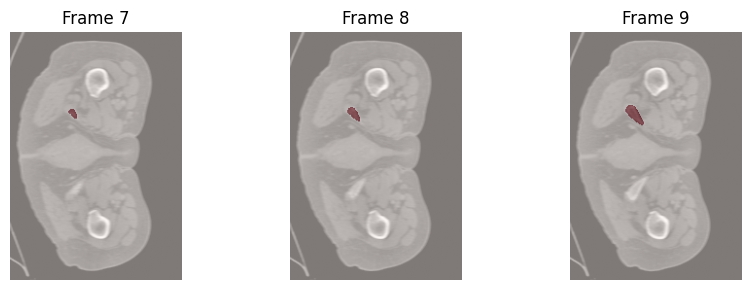

In [16]:
visualize_video_segmentation(ct_slices, predicted_masks)

We now evaluate

In [20]:
mean_dice, mean_iou, mean_hausdorff = compute_segmentation_metrics(predicted_masks, gt_slices)
print(f"Mean Dice: {mean_dice:.4f}, Mean IoU: {mean_iou:.4f}, Mean 95th Percentile Hausdorff Distance: {mean_hausdorff:.4f}")

c:\Users\pamar\Documents\GitHub\ML-P2-Sam2\.venv\Lib\site-packages\monai\utils\deprecate_utils.py:221: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)


Mean Dice: 0.9503, Mean IoU: 0.9075, Mean 95th Percentile Hausdorff Distance: 0.6667


In [21]:

results_per_slice = compute_segmentation_metrics_per_slice(predicted_masks, gt_slices)

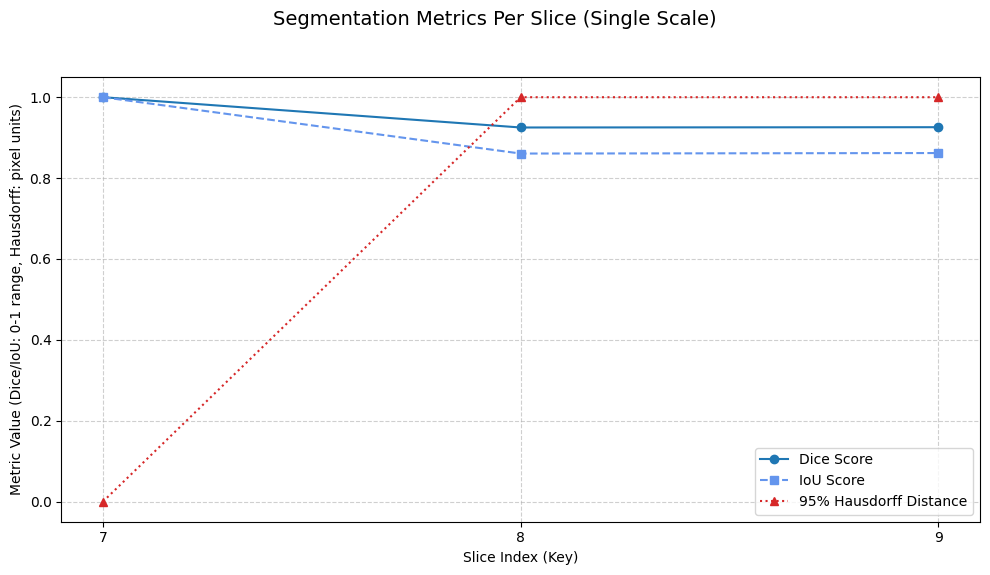

In [22]:

visualize_metrics_per_slice(results_per_slice)